# Card Fraud Triage: Exploratory Data Analysis

This notebook explores the cleaned transaction data. It is descriptive only: it does not change datasets or train a model. `Time` is elapsed seconds from the first recorded transaction, not a clock time.

## 1. Imports, configuration, and plotting setup

Find the project root from either the repository root or `notebooks/`, import shared paths and the seed from `src/config.py`, and configure reproducible plotting.

In [1]:
import json
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "config.py").is_file():
    raise FileNotFoundError("Could not locate src/config.py from the current directory")
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.config import ARTIFACTS, CLEAN_PATH, SEED

np.random.seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: "{:,.4f}".format(value))
print("Project root:", PROJECT_ROOT)
print("Cleaned data:", CLEAN_PATH)
print("Seed:", SEED)

Project root: /Users/yuvrajchandravansi/Desktop/card-fraud-triage
Cleaned data: /Users/yuvrajchandravansi/Desktop/card-fraud-triage/data/processed/creditcard_clean.csv
Seed: 42


## 2. Load the cleaned dataset

Load the configured cleaned CSV and stop with a clear error if it is missing or empty.

In [2]:
if not CLEAN_PATH.is_file():
    raise FileNotFoundError(
        "Cleaned dataset not found at {}. Run notebooks/cleaning.ipynb first.".format(CLEAN_PATH)
    )

df = pd.read_csv(CLEAN_PATH)
if df.empty:
    raise ValueError("Cleaned dataset contains no transaction rows")
print("Loaded cleaned dataset: {:,} rows x {} columns".format(*df.shape))

Loaded cleaned dataset: 283,726 rows x 31 columns


## 3. Schema, data quality, and integrity

Check the exact expected schema and the cleaned-data invariants before analysis. Display measured counts and dtypes, then stop with a descriptive error if required fields or data-quality invariants fail. Duplicate rows are reported, never removed here.

In [3]:
required_columns = ["Time"] + ["V{}".format(i) for i in range(1, 29)] + ["Amount", "Class"]
missing_columns = [column for column in required_columns if column not in df.columns]
unexpected_columns = [column for column in df.columns if column not in required_columns]
non_numeric_columns = [column for column in df.columns if not pd.api.types.is_numeric_dtype(df[column])]
duplicate_columns = df.columns[df.columns.duplicated()].tolist()
if missing_columns or unexpected_columns or non_numeric_columns or duplicate_columns:
    raise ValueError(
        "Schema validation failed: missing={}, unexpected={}, non_numeric={}, duplicate_names={}".format(
            missing_columns, unexpected_columns, non_numeric_columns, duplicate_columns
        )
    )

missing_by_column = df.isna().sum().astype(int)
missing_count = int(missing_by_column.sum())
infinite_count = int(np.isinf(df.to_numpy(dtype=float)).sum())
duplicate_count = int(df.duplicated().sum())
class_counts = df["Class"].value_counts().reindex([0, 1], fill_value=0)
class_values = sorted(df["Class"].unique().tolist())
negative_amount_count = int((df["Amount"] < 0).sum())
negative_time_count = int((df["Time"] < 0).sum())
memory_bytes = df.memory_usage(deep=True)

quality_checks = pd.DataFrame(
    [
        ("Dataset shape", "{:,} rows x {} columns".format(*df.shape), True),
        ("All columns numeric", str(df.dtypes.astype(str).value_counts().to_dict()), True),
        ("Missing values", "{} total; {} columns affected".format(missing_count, int((missing_by_column > 0).sum())), missing_count == 0),
        ("Infinite numeric values", str(infinite_count), infinite_count == 0),
        ("Exact duplicate rows", str(duplicate_count), duplicate_count == 0),
        ("Class labels", str(class_values), class_values == [0, 1]),
        ("Both classes present", "legitimate={}, fraud={}".format(int(class_counts.loc[0]), int(class_counts.loc[1])), bool((class_counts > 0).all())),
        ("Negative Amount rows", str(negative_amount_count), negative_amount_count == 0),
        ("Negative Time rows", str(negative_time_count), negative_time_count == 0),
        ("Memory usage", "{:.2f} MiB".format(memory_bytes.sum() / (1024 ** 2)), True),
    ],
    columns=["check", "observed", "passed"],
).set_index("check")
display(quality_checks)
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_values": missing_by_column, "memory_bytes": memory_bytes.drop("Index")}))
failed_checks = quality_checks.index[~quality_checks["passed"]].tolist()
if failed_checks:
    raise ValueError("Cleaned-data integrity checks failed: {}".format(failed_checks))
print("All schema and data-quality checks passed.")

,observed,passed
check,,
Dataset shape,"283,726 rows x 31 columns",True
All columns numeric,"{'float64': 30, 'int64': 1}",True
Missing values,0 total; 0 columns affected,True
Infinite numeric values,0,True
Exact duplicate rows,0,True
Class labels,"[0, 1]",True
Both classes present,"legitimate=283253, fraud=473",True
Negative Amount rows,0,True
Negative Time rows,0,True


,dtype,missing_values,memory_bytes
Time,float64,0,2269808
V1,float64,0,2269808
V2,float64,0,2269808
V3,float64,0,2269808
V4,float64,0,2269808
V5,float64,0,2269808
V6,float64,0,2269808
V7,float64,0,2269808
V8,float64,0,2269808
V9,float64,0,2269808


All schema and data-quality checks passed.


## 4. Cleaning report context

Check that the cleaning report agrees with the loaded CSV's shape, duplicate counts, and fraud counts. Exact duplicates match on every column, but can still represent distinct repeated transactions.

In [4]:
CLEAN_REPORT_PATH = ARTIFACTS / "clean_report.json"
if not CLEAN_REPORT_PATH.is_file():
    raise FileNotFoundError("Cleaning report not found: {}. Run notebooks/cleaning.ipynb first.".format(CLEAN_REPORT_PATH))

clean_report = json.loads(CLEAN_REPORT_PATH.read_text(encoding="utf-8"))
raw_shape = clean_report["raw_shape"]
clean_shape = clean_report["clean_shape"]
rows_removed = clean_report["rows_removed"]
duplicate_analysis = clean_report["duplicate_analysis"]
before = clean_report["before_cleaning"]
after = clean_report["after_cleaning"]

if clean_shape != list(df.shape):
    raise ValueError("Cleaning report shape {} does not match cleaned CSV {}".format(clean_shape, list(df.shape)))
if raw_shape[1] != df.shape[1] or raw_shape[0] - len(df) != rows_removed["total"]:
    raise ValueError("Cleaning report row/column totals do not match the loaded CSV")
if rows_removed["exact_duplicates"] + rows_removed["missing_or_infinite_values"] != rows_removed["total"]:
    raise ValueError("Cleaning report removal counts do not add up")
if duplicate_analysis["duplicate_rows_labelled_fraud"] + duplicate_analysis["duplicate_rows_labelled_legitimate"] != rows_removed["exact_duplicates"]:
    raise ValueError("Cleaning report duplicate class counts do not add up")
if before["Rows"] != raw_shape[0] or after["Rows"] != len(df):
    raise ValueError("Cleaning report before/after row counts do not match")
if before["Exact duplicate rows"] != rows_removed["exact_duplicates"] or after["Exact duplicate rows"] != duplicate_count:
    raise ValueError("Cleaning report duplicate counts do not match the cleaned CSV")
if after["Fraud transactions"] != int(class_counts.loc[1]):
    raise ValueError("Cleaning report fraud count does not match the cleaned CSV")
if rows_removed["missing_or_infinite_values"] == 0 and before["Fraud transactions"] - after["Fraud transactions"] != duplicate_analysis["duplicate_rows_labelled_fraud"]:
    raise ValueError("Cleaning report fraud removal does not match the duplicate audit")

cleaning_context = {
    "raw_shape": raw_shape,
    "clean_shape": clean_shape,
    "exact_duplicate_rows_removed": rows_removed["exact_duplicates"],
    "duplicate_rows_labeled_fraud_removed": duplicate_analysis["duplicate_rows_labelled_fraud"],
    "duplicate_rows_labeled_legitimate_removed": duplicate_analysis["duplicate_rows_labelled_legitimate"],
    "fraud_count_before_cleaning": before["Fraud transactions"],
    "fraud_count_after_cleaning": after["Fraud transactions"],
}
print("Exact duplicates match on every column; removal can also discard distinct repeated transactions.")
display(pd.Series(cleaning_context, name="cleaning report").to_frame())

Exact duplicates match on every column; removal can also discard distinct repeated transactions.


,cleaning report
raw_shape,"[284807, 31]"
clean_shape,"[283726, 31]"
exact_duplicate_rows_removed,1081
duplicate_rows_labeled_fraud_removed,19
duplicate_rows_labeled_legitimate_removed,1062
fraud_count_before_cleaning,492
fraud_count_after_cleaning,473


## 5. Descriptive statistics

Summarize continuous transaction fields with quartiles, IQR, high percentiles, and skewness. `Class` is binary, so it is excluded from continuous-feature skewness interpretation and summarized in the class section instead.

In [5]:
continuous_columns = ["Time"] + ["V{}".format(i) for i in range(1, 29)] + ["Amount"]
continuous_summary = df[continuous_columns].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).T
continuous_summary["IQR"] = continuous_summary["75%"] - continuous_summary["25%"]
continuous_summary["skewness"] = df[continuous_columns].skew()
display(continuous_summary)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,IQR,skewness
Time,"283,726.0000","94,811.0776","47,481.0479",0.0000,"54,204.7500","84,692.5000","139,298.0000","157,631.0000","164,138.7500","170,557.7500","172,792.0000","85,093.2500",-0.0356
V1,"283,726.0000",0.0059,1.9480,-56.4075,-0.9160,0.0204,1.3161,2.0158,2.0814,2.2373,2.4549,2.2320,-3.2733
V2,"283,726.0000",-0.0041,1.6467,-72.7157,-0.6003,0.0639,0.8003,1.3195,1.7961,3.7663,22.0577,1.4006,-4.6952
V3,"283,726.0000",0.0016,1.5087,-48.3256,-0.8897,0.1800,1.0270,1.6756,2.0621,2.7259,9.3826,1.9166,-2.1520
V4,"283,726.0000",-0.0030,1.4142,-5.6832,-0.8501,-0.0222,0.7396,1.4792,2.5566,4.2444,16.8753,1.5898,0.6715
V5,"283,726.0000",0.0018,1.3770,-113.7433,-0.6898,-0.0535,0.6122,1.4069,2.0997,3.4270,34.8017,1.3020,-2.4141
V6,"283,726.0000",-0.0011,1.3319,-26.1605,-0.7690,-0.2752,0.3968,1.5070,3.1594,4.1996,73.3016,1.1658,1.8299
V7,"283,726.0000",0.0018,1.2277,-43.5572,-0.5525,0.0409,0.5705,1.0390,1.4071,2.6800,120.5895,1.1230,2.8903
V8,"283,726.0000",-0.0009,1.1791,-73.2167,-0.2088,0.0219,0.3257,0.7652,1.0423,2.0442,20.0072,0.5345,-8.3110
V9,"283,726.0000",-0.0016,1.0955,-13.4341,-0.6442,-0.0526,0.5960,1.3001,1.7786,2.9763,15.5950,1.2402,0.5377


## 6. Class imbalance

Calculate counts, prevalence, and the legitimate-to-fraud ratio from the loaded data. Keep the logarithmic count chart; the percentage chart also uses a logarithmic axis so the minority share is legible. Exact percentages, counts, and the ratio are annotated directly.

,transactions,percentage
Legitimate (0),283253,99.8333
Fraud (1),473,0.1667


Fraud prevalence: 0.1667%
Legitimate-to-fraud ratio: 598.8:1


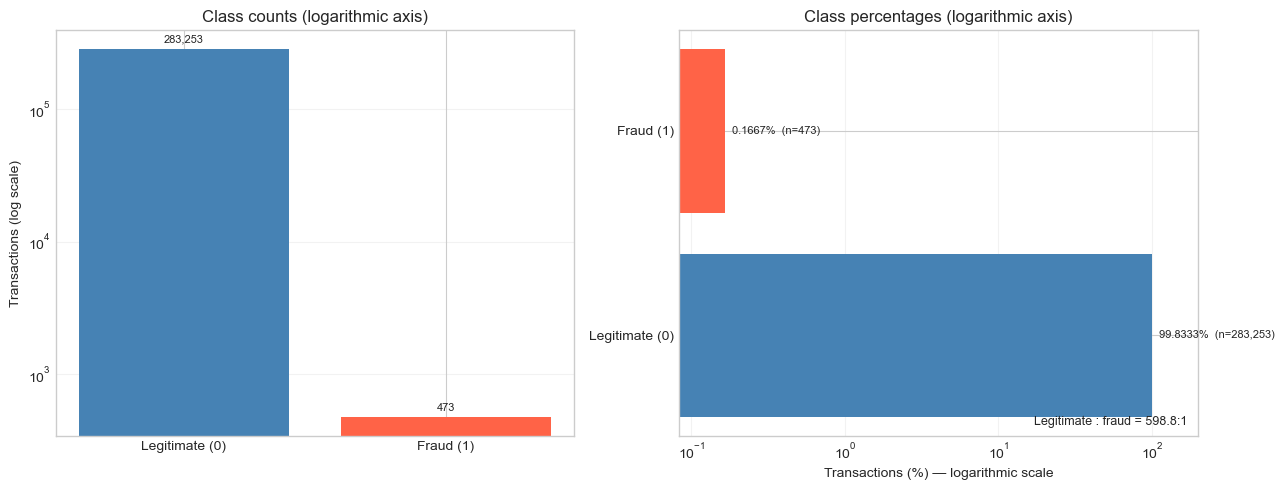

In [6]:
legitimate_count = int(class_counts.loc[0])
fraud_count = int(class_counts.loc[1])
total_count = int(len(df))
fraud_prevalence = fraud_count / total_count
imbalance_ratio = legitimate_count / fraud_count
class_summary = pd.DataFrame(
    {"transactions": [legitimate_count, fraud_count], "percentage": [legitimate_count / total_count * 100, fraud_prevalence * 100]},
    index=["Legitimate (0)", "Fraud (1)"],
)
display(class_summary)
print("Fraud prevalence: {:.4f}%".format(fraud_prevalence * 100))
print("Legitimate-to-fraud ratio: {:.1f}:1".format(imbalance_ratio))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
count_bars = axes[0].bar(class_summary.index, class_summary["transactions"], color=["steelblue", "tomato"])
axes[0].set_yscale("log")
axes[0].set_title("Class counts (logarithmic axis)")
axes[0].set_ylabel("Transactions (log scale)")
axes[0].bar_label(count_bars, labels=["{:,}".format(value) for value in class_summary["transactions"]], padding=3, fontsize=8)

percentage_bars = axes[1].barh(
    class_summary.index, class_summary["percentage"], color=["steelblue", "tomato"]
)
axes[1].set_xscale("log")
axes[1].set_xlim(max(class_summary["percentage"].min() / 2, 0.001), 200)
axes[1].set_title("Class percentages (logarithmic axis)")
axes[1].set_xlabel("Transactions (%) — logarithmic scale")
axes[1].bar_label(
    percentage_bars,
    labels=["{:.4f}%  (n={:,})".format(row["percentage"], int(row["transactions"])) for _, row in class_summary.iterrows()],
    padding=5,
    fontsize=8,
)
axes[1].text(
    0.98, 0.02, "Legitimate : fraud = {:.1f}:1".format(imbalance_ratio),
    transform=axes[1].transAxes, ha="right", va="bottom", fontsize=9,
)
axes[0].grid(axis="y", alpha=0.25)  # vertical bar chart → horizontal grid lines
axes[1].grid(axis="x", alpha=0.25)  # horizontal bar chart → vertical grid lines
plt.tight_layout()
plt.show()

## 7. Temporal analysis: elapsed time

`Time` is elapsed seconds since the first transaction; the dataset does not provide a timezone or clock-time anchor. Analyze one-hour elapsed-time bins only. Display transaction and fraud counts alongside rates so a high rate in a small bin is not mistaken for a large fraud volume. Bins below half the median bin count are flagged as small-sample bins; this is a descriptive flag, not a statistical significance threshold.

### 7a. Overall transaction volume over elapsed time

A raw histogram of all transactions across the 48-hour window. Shows whether volume is uniformly distributed or has high/low activity periods.

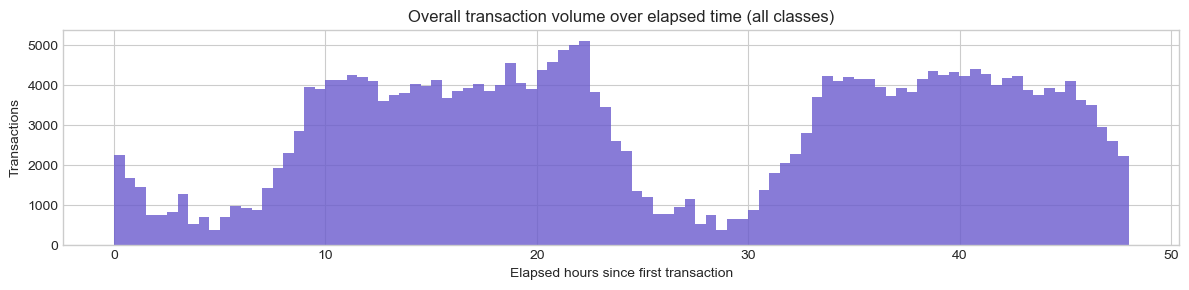

In [7]:
fig, ax = plt.subplots(figsize=(12, 3))
ax.hist(df["Time"] / 3600, bins=96, color="slateblue", edgecolor="none", alpha=0.8)
ax.set_title("Overall transaction volume over elapsed time (all classes)")
ax.set_xlabel("Elapsed hours since first transaction")
ax.set_ylabel("Transactions")
plt.tight_layout()
plt.show()

Elapsed time range: 0.00–48.00 hours
Highest observed one-hour-bin rate: elapsed bin 26–27, 1.5562% from 1735 transactions (27 frauds). This is a sample observation, not evidence that this elapsed period is inherently riskier.
Small-sample flag: bins with fewer than 3,844 transactions (50% of the median bin count).
Flagged elapsed-time bins: [1, 2, 3, 4, 5, 6, 7, 24, 25, 26, 27, 28, 29, 30]


,transactions,frauds,fraud_rate_percent,small_sample
elapsed_hour_bin,,,,
0,3931,2,0.0509,False
1,2213,2,0.0904,True
2,1573,21,1.3350,True
3,1818,13,0.7151,True
4,1082,6,0.5545,True
5,1679,11,0.6552,True
6,1822,3,0.1647,True
7,3366,23,0.6833,True
8,5148,5,0.0971,False


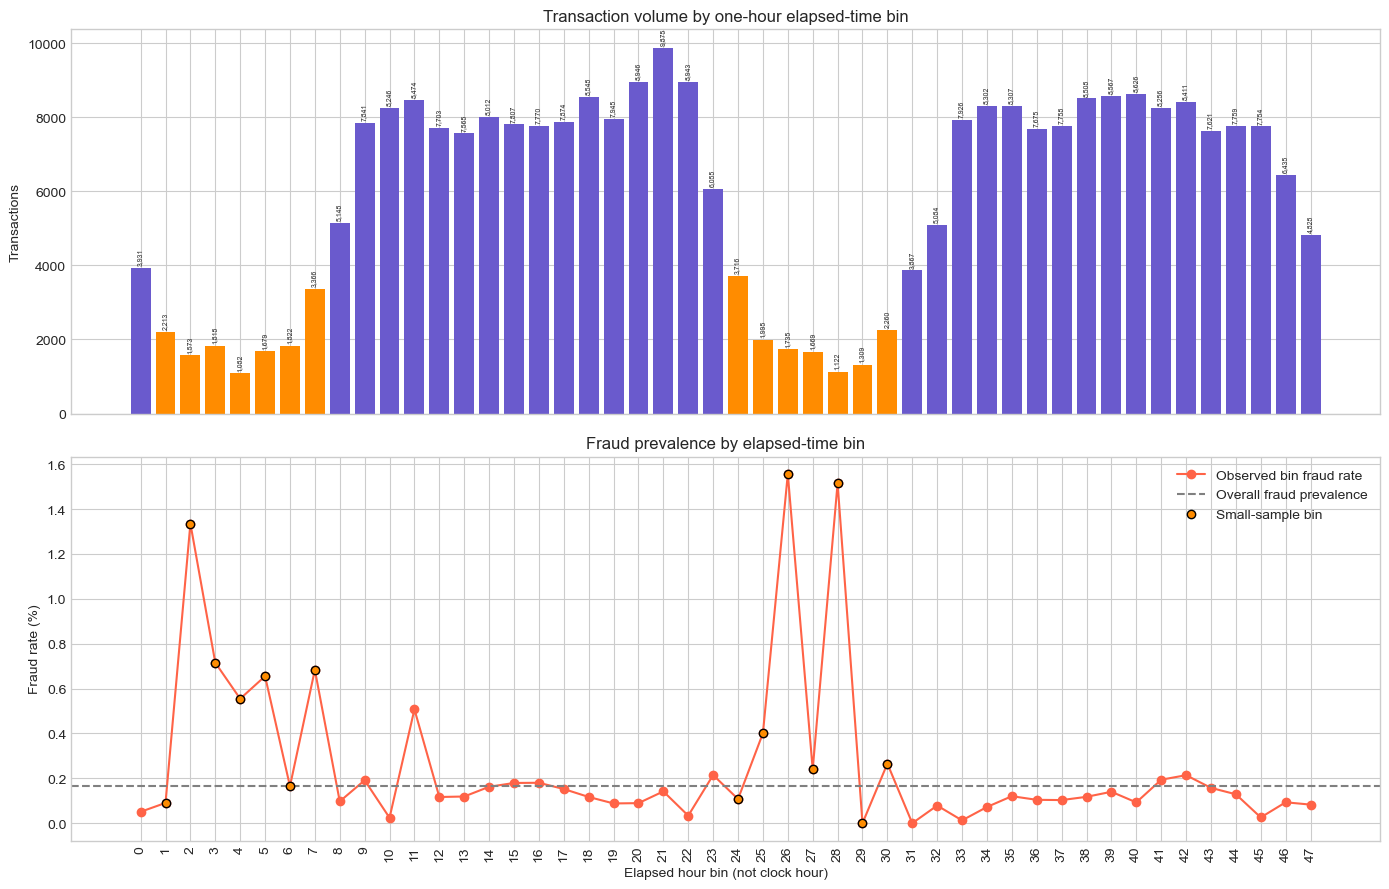

In [8]:
elapsed_hours = df["Time"] / 3600
elapsed_hour_bin = np.floor(df["Time"] / 3600).astype(int)
hourly_stats = df.groupby(elapsed_hour_bin)["Class"].agg(transactions="size", frauds="sum").rename_axis("elapsed_hour_bin")
hourly_stats["fraud_rate_percent"] = np.where(
    hourly_stats["transactions"] > 0,
    hourly_stats["frauds"] / hourly_stats["transactions"] * 100,
    np.nan,
)
small_bin_threshold = max(1, int(np.floor(hourly_stats["transactions"].median() * 0.5)))
hourly_stats["small_sample"] = hourly_stats["transactions"] < small_bin_threshold
peak_bin = int(hourly_stats["fraud_rate_percent"].idxmax())
peak_bin_row = hourly_stats.loc[peak_bin]
print("Elapsed time range: {:.2f}–{:.2f} hours".format(elapsed_hours.min(), elapsed_hours.max()))
print(
    "Highest observed one-hour-bin rate: elapsed bin {}–{}, {:.4f}% "
    "from {} transactions ({} frauds). This is a sample observation, not evidence "
    "that this elapsed period is inherently riskier.".format(
        peak_bin, peak_bin + 1, peak_bin_row["fraud_rate_percent"],
        int(peak_bin_row["transactions"]), int(peak_bin_row["frauds"])
    )
)
print("Small-sample flag: bins with fewer than {:,} transactions (50% of the median bin count).".format(small_bin_threshold))
print("Flagged elapsed-time bins:", hourly_stats.index[hourly_stats["small_sample"]].tolist())
display(hourly_stats)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
bar_colors = ["darkorange" if flagged else "slateblue" for flagged in hourly_stats["small_sample"]]
volume_bars = axes[0].bar(hourly_stats.index.astype(str), hourly_stats["transactions"], color=bar_colors)
axes[0].bar_label(volume_bars, labels=["{:,}".format(int(value)) for value in hourly_stats["transactions"]], padding=2, fontsize=5, rotation=90)
axes[0].set_title("Transaction volume by one-hour elapsed-time bin")
axes[0].set_ylabel("Transactions")
hourly_stats["fraud_rate_percent"].plot(kind="line", marker="o", color="tomato", ax=axes[1], label="Observed bin fraud rate")
axes[1].axhline(fraud_prevalence * 100, color="gray", linestyle="--", label="Overall fraud prevalence")
small_bins = hourly_stats[hourly_stats["small_sample"]]
if not small_bins.empty:
    axes[1].scatter(small_bins.index, small_bins["fraud_rate_percent"], color="darkorange", edgecolor="black", zorder=3, label="Small-sample bin")
axes[1].set_title("Fraud prevalence by elapsed-time bin")
axes[1].set_xlabel("Elapsed hour bin (not clock hour)")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].legend()
axes[1].tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()

## 8. Transaction amount profiling

Compare amount distributions by class, including quartiles and upper percentiles. The shared log1p histogram bins make the class distributions comparable; the ECDF shows typical values and tails. `log1p` is used only for visualization. Amount categories are descriptive value ranges, not validated fraud-risk tiers.

,count,mean,std,min,25%,50%,75%,90%,95%,99%,99.9%,max,skewness
Class,,,,,,,,,,,,,
Legitimate (0),"283,253.0000",88.4136,250.3790,0.0000,5.6700,22.0000,77.4600,203.0000,365.0000,"1,018.0576","3,012.9254","25,691.1600",17.0043
Fraud (1),473.0000,123.8719,260.2110,0.0000,1.0000,9.8200,105.8900,348.6520,655.8200,"1,364.1368","1,976.6283","2,125.8700",3.7245


,transactions,frauds,fraud_rate_percent
amount_category,,,
0,1808,25,1.3827
"(0, 10]",98013,213,0.2173
"(10, 100]",127506,110,0.0863
"(100, 500]",47290,91,0.1924
"(500, 1,000]",6174,25,0.4049
">1,000",2935,9,0.3066


Zero-amount transactions: 1808 (25 labeled fraud)


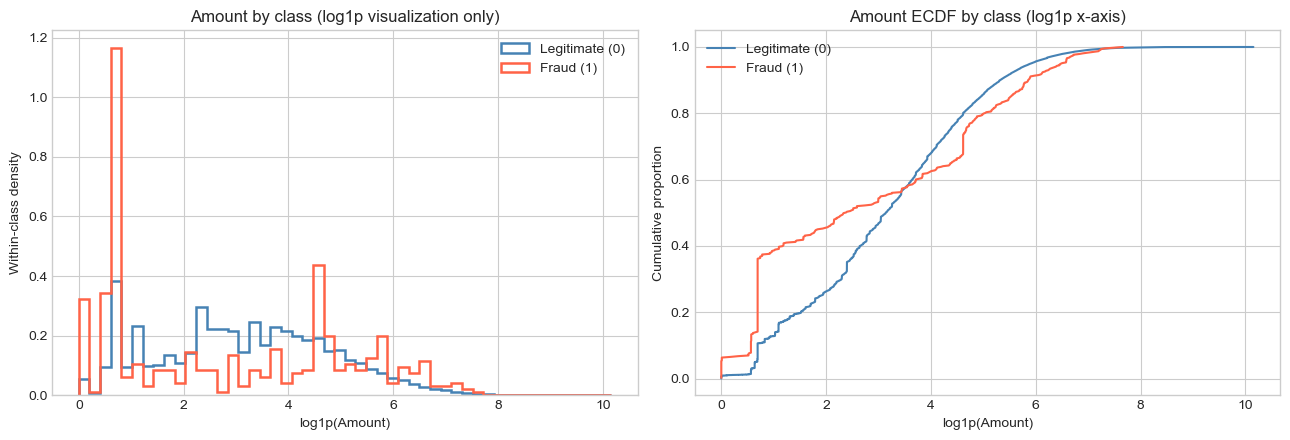

In [9]:
amount_percentiles = [0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
amount_by_class = df.groupby("Class")["Amount"].describe(percentiles=amount_percentiles)
amount_by_class["skewness"] = df.groupby("Class")["Amount"].skew()
display(amount_by_class.rename(index={0: "Legitimate (0)", 1: "Fraud (1)"}))

amount_labels = ["0", "(0, 10]", "(10, 100]", "(100, 500]", "(500, 1,000]", ">1,000"]
# Lower bound -1 (not 0) so that include_lowest=True captures Amount == 0;
# negative amounts are already confirmed absent by the schema check above.
amount_bins = [-1, 0, 10, 100, 500, 1000, np.inf]
amount_tier = pd.cut(df["Amount"], bins=amount_bins, labels=amount_labels, include_lowest=True)
tier_summary = df.assign(amount_category=amount_tier).groupby("amount_category", observed=False)["Class"].agg(
    transactions="size", frauds="sum"
)
tier_summary["fraud_rate_percent"] = np.where(
    tier_summary["transactions"] > 0,
    tier_summary["frauds"] / tier_summary["transactions"] * 100,
    np.nan,
)
display(tier_summary)
zero_amount_count = int((df["Amount"] == 0).sum())
zero_amount_fraud_count = int(((df["Amount"] == 0) & (df["Class"] == 1)).sum())
print("Zero-amount transactions: {} ({} labeled fraud)".format(zero_amount_count, zero_amount_fraud_count))

log_amount = np.log1p(df["Amount"])
shared_log_bins = np.linspace(float(log_amount.min()), float(log_amount.max()), 51)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for class_value, label, color in [(0, "Legitimate (0)", "steelblue"), (1, "Fraud (1)", "tomato")]:
    values = log_amount.loc[df["Class"] == class_value]
    axes[0].hist(values, bins=shared_log_bins, density=True, histtype="step", linewidth=1.8, label=label, color=color)
axes[0].set_title("Amount by class (log1p visualization only)")
axes[0].set_xlabel("log1p(Amount)")
axes[0].set_ylabel("Within-class density")
axes[0].legend()

for class_value, label, color in [(0, "Legitimate (0)", "steelblue"), (1, "Fraud (1)", "tomato")]:
    values = np.sort(log_amount.loc[df["Class"] == class_value].to_numpy())
    cumulative_probability = np.arange(1, len(values) + 1) / float(len(values))
    axes[1].plot(values, cumulative_probability, label=label, color=color)
axes[1].set_title("Amount ECDF by class (log1p x-axis)")
axes[1].set_xlabel("log1p(Amount)")
axes[1].set_ylabel("Cumulative proportion")
axes[1].legend()
plt.tight_layout()
plt.show()

### 8a. Amount distribution by class — box plot

Box plots (outliers hidden) make the median and IQR difference between legitimate and fraud transactions immediately visible. Use this alongside the histogram and ECDF for a complete picture.

/var/folders/ps/7lkn6rwn7ng3w5rj5vfh7h4r0000gn/T/ipykernel_4309/4028783344.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(
/var/folders/ps/7lkn6rwn7ng3w5rj5vfh7h4r0000gn/T/ipykernel_4309/4028783344.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


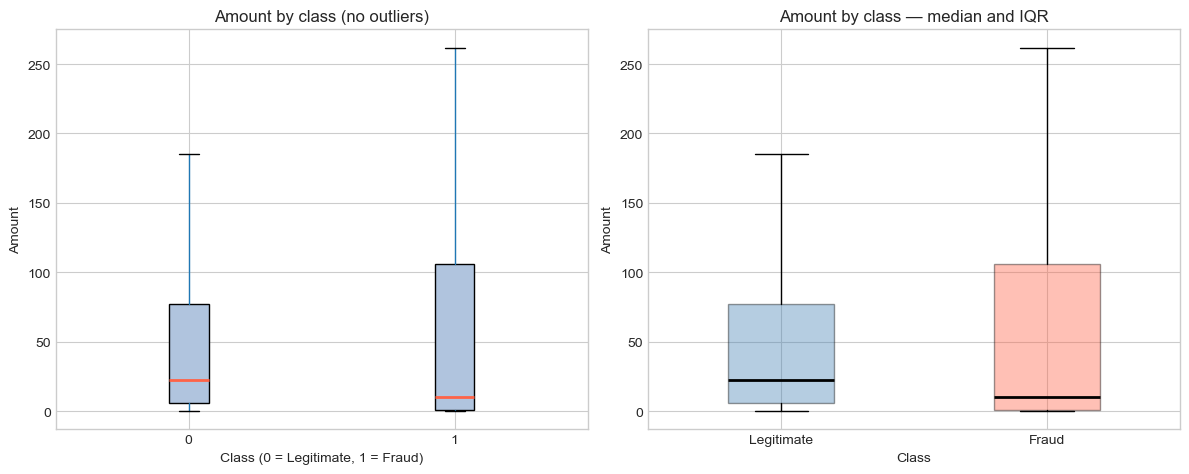

Legitimate: median=22.00, IQR=5.67–77.46, max=25691.16
Fraud: median=9.82, IQR=1.00–105.89, max=2125.87


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Box plot without outliers (showfliers=False keeps the chart readable
# given the extreme right-tail of the Amount distribution)
bp = df.boxplot(
    column="Amount", by="Class", ax=axes[0],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightsteelblue"),
    medianprops=dict(color="tomato", linewidth=2),
)
axes[0].set_title("Amount by class (no outliers)")
axes[0].set_xlabel("Class (0 = Legitimate, 1 = Fraud)")
axes[0].set_ylabel("Amount")
plt.suptitle("")  # Remove pandas auto-title

# Box plot WITH outliers shown via strip to give the full picture
for class_value, label, color in [(0, "Legitimate", "steelblue"), (1, "Fraud", "tomato")]:
    subset = df.loc[df["Class"] == class_value, "Amount"]
    axes[1].boxplot(
        subset, positions=[class_value], widths=0.4,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.4),
        medianprops=dict(color="black", linewidth=2),
        showfliers=False,
        labels=[label],
    )
axes[1].set_title("Amount by class — median and IQR")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Amount")

plt.tight_layout()
plt.show()

# Print the key stats clearly
for class_value, label in [(0, "Legitimate"), (1, "Fraud")]:
    subset = df.loc[df["Class"] == class_value, "Amount"]
    print("{}: median={:.2f}, IQR={:.2f}–{:.2f}, max={:.2f}".format(
        label, subset.median(), subset.quantile(0.25), subset.quantile(0.75), subset.max()
    ))

## 9. Feature associations and distributions

Calculate Pearson and Spearman associations with `Class` for `V1`–`V28` and `Amount`. Rank by absolute Pearson correlation while retaining signs, and plot class-conditional distributions for the top features. Associations are descriptive, not causal. Exclude `Class` from any model inputs.

,pearson_with_class,spearman_with_class
V17,-0.3135,-0.0425
V14,-0.2934,-0.0632
V12,-0.2507,-0.0614
V10,-0.2070,-0.0580
V16,-0.1872,-0.0483
V3,-0.1823,-0.0577
V7,-0.1723,-0.0466
V11,0.1491,0.0586
V4,0.1293,0.0617
V18,-0.1053,-0.0330


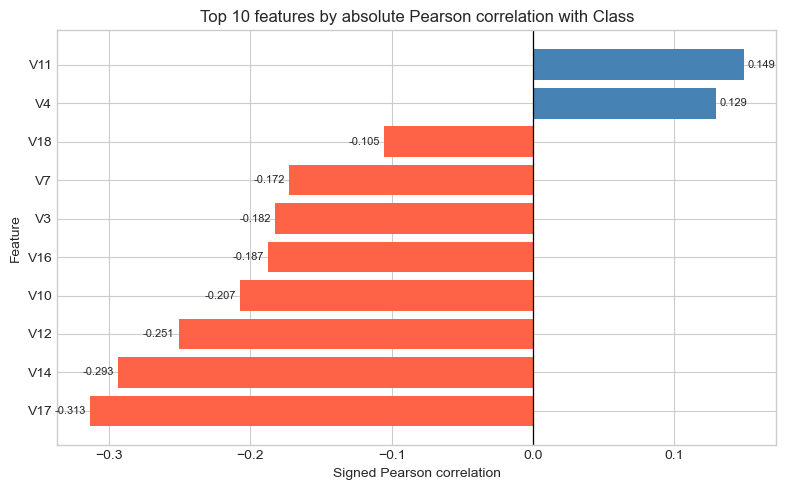

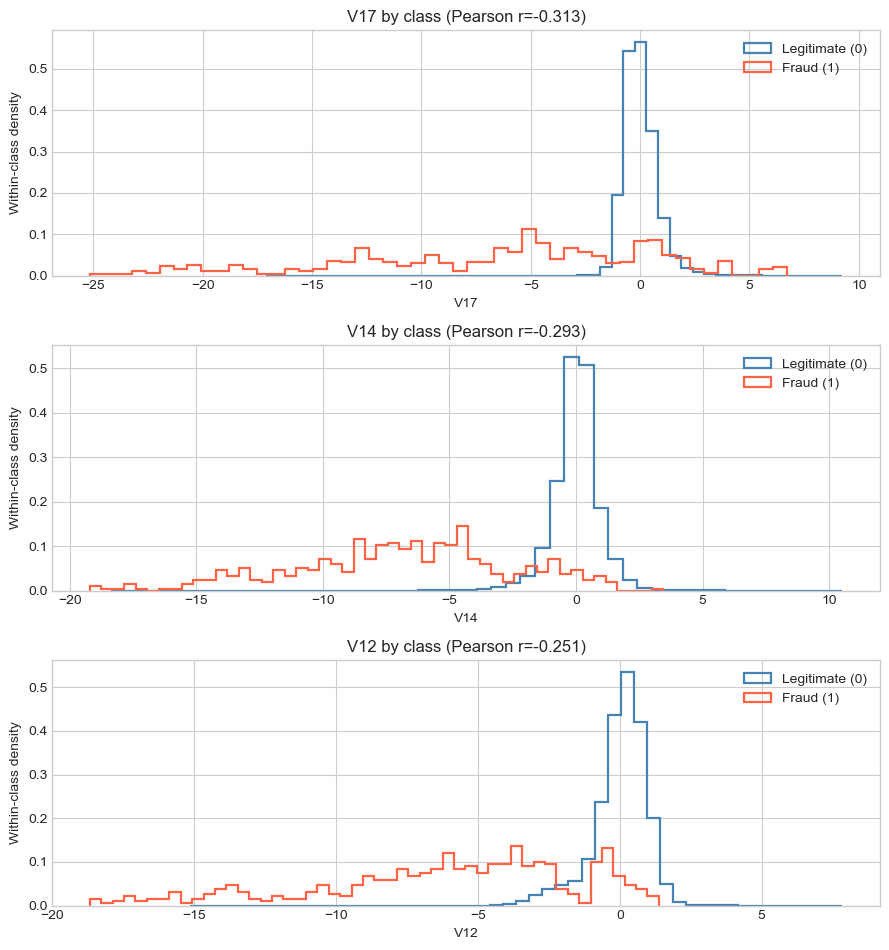

In [11]:
association_features = ["V{}".format(i) for i in range(1, 29)] + ["Amount"]
pearson = df[association_features + ["Class"]].corr(method="pearson")["Class"].drop("Class")
spearman = df[association_features + ["Class"]].corr(method="spearman")["Class"].drop("Class")
feature_associations = pd.DataFrame({"pearson_with_class": pearson, "spearman_with_class": spearman})
feature_associations["absolute_pearson"] = feature_associations["pearson_with_class"].abs()
feature_associations = feature_associations.sort_values("absolute_pearson", ascending=False)
top_10_associations = feature_associations.head(10)
display(top_10_associations.drop(columns="absolute_pearson"))

top_10_plot = top_10_associations.sort_values("pearson_with_class")
association_colors = ["tomato" if value < 0 else "steelblue" for value in top_10_plot["pearson_with_class"]]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top_10_plot.index, top_10_plot["pearson_with_class"], color=association_colors)
ax.axvline(0, color="black", linewidth=0.9)
ax.bar_label(bars, labels=["{:.3f}".format(value) for value in top_10_plot["pearson_with_class"]], padding=3, fontsize=8)
ax.set_title("Top 10 features by absolute Pearson correlation with Class")
ax.set_xlabel("Signed Pearson correlation")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

top_distribution_features = feature_associations.head(3).index.tolist()
fig, axes = plt.subplots(len(top_distribution_features), 1, figsize=(9, 3.2 * len(top_distribution_features)))
for ax, feature in zip(np.atleast_1d(axes), top_distribution_features):
    for class_value, label, color in [(0, "Legitimate (0)", "steelblue"), (1, "Fraud (1)", "tomato")]:
        ax.hist(
            df.loc[df["Class"] == class_value, feature], bins=50, density=True,
            histtype="step", linewidth=1.6, label=label, color=color
        )
    ax.set_title("{} by class (Pearson r={:.3f})".format(feature, pearson.loc[feature]))
    ax.set_xlabel(feature)
    ax.set_ylabel("Within-class density")
    ax.legend()
plt.tight_layout()
plt.show()

## 10. PCA-feature correlation diagnostics

Compute the full-dataset pairwise correlation matrix for all `V1`–`V28` columns and report the largest absolute off-diagonal correlation. Also summarize class-conditional maxima. These anonymized PCA-derived features need not be perfectly uncorrelated in the combined data; class-conditional correlations can differ. `Time` and `Amount` are not included in this PCA-feature diagnostic.

Maximum absolute off-diagonal correlation: 0.018892 between V8 and V21


,maximum_absolute_off_diagonal_correlation
Class,
0,0.1714
1,0.9719


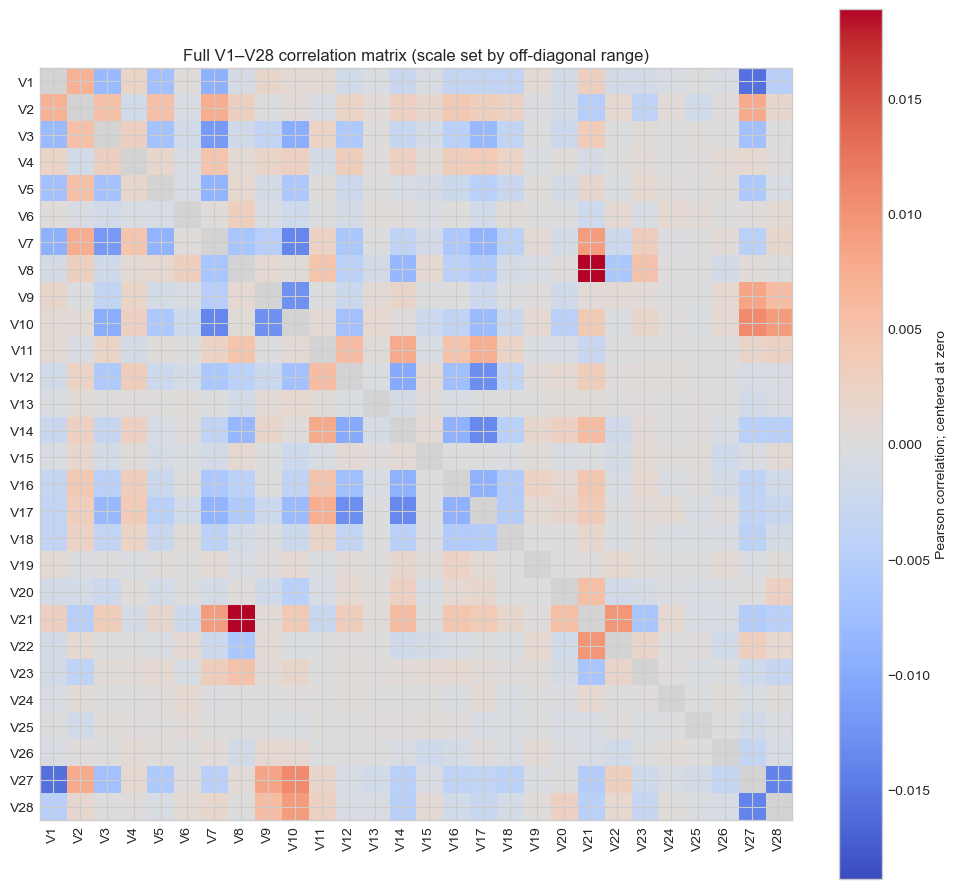

In [12]:
pca_features = ["V{}".format(i) for i in range(1, 29)]
pca_correlation = df[pca_features].corr(method="pearson")
off_diagonal = pca_correlation.where(np.triu(np.ones(pca_correlation.shape), k=1).astype(bool))
off_diagonal_values = off_diagonal.stack()
max_pair = off_diagonal_values.abs().idxmax()
max_abs_correlation = float(off_diagonal.loc[max_pair[0], max_pair[1]])
print("Maximum absolute off-diagonal correlation: {:.6f} between {} and {}".format(
    abs(max_abs_correlation), max_pair[0], max_pair[1]
))

class_conditional_max = {}
for class_value in (0, 1):
    class_corr = df.loc[df["Class"] == class_value, pca_features].corr(method="pearson")
    class_off_diagonal = class_corr.where(np.triu(np.ones(class_corr.shape), k=1).astype(bool))
    class_conditional_max[str(class_value)] = float(class_off_diagonal.abs().stack().max())
display(pd.Series(class_conditional_max, name="maximum_absolute_off_diagonal_correlation").rename_axis("Class").to_frame())

color_limit = max(float(off_diagonal_values.abs().max()), np.finfo(float).eps)
heatmap_values = np.ma.masked_array(pca_correlation.to_numpy(), mask=np.eye(len(pca_features), dtype=bool))
heatmap_cmap = plt.get_cmap("coolwarm").copy()
heatmap_cmap.set_bad("lightgray")
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(heatmap_values, cmap=heatmap_cmap, vmin=-color_limit, vmax=color_limit)
ax.set_xticks(range(len(pca_features)))
ax.set_yticks(range(len(pca_features)))
ax.set_xticklabels(pca_features, rotation=90)
ax.set_yticklabels(pca_features)
ax.set_title("Full V1–V28 correlation matrix (scale set by off-diagonal range)")
fig.colorbar(image, ax=ax, label="Pearson correlation; centered at zero")
plt.tight_layout()
plt.show()

## 11. Export the EDA report

Save the measured results to `artifacts/eda_report.json` using the repository configuration and a relative dataset path.

In [13]:
def json_safe(value):
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if value is None or value is pd.NA:
        return None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

eda_report = {
    "project": "Card Fraud Triage",
    "notebook": "notebooks/eda.ipynb",
    "dataset_path": CLEAN_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "dataset_shape": [int(df.shape[0]), int(df.shape[1])],
    "class_imbalance": {
        "legitimate_count": legitimate_count,
        "fraud_count": fraud_count,
        "total_count": total_count,
        "fraud_prevalence": fraud_prevalence,
        "legitimate_to_fraud_ratio": imbalance_ratio,
    },
    "data_quality": {
        name: {"observed": row["observed"], "passed": bool(row["passed"])}
        for name, row in quality_checks.iterrows()
    },
    "continuous_descriptive_statistics": continuous_summary.to_dict(orient="index"),
    "amount_profiling": {
        "by_class": amount_by_class.to_dict(orient="index"),
        "categories": [
            {"category": str(category), **row.to_dict()}
            for category, row in tier_summary.iterrows()
        ],
        "zero_amount_count": zero_amount_count,
        "zero_amount_fraud_count": zero_amount_fraud_count,
    },
    "temporal_analysis": {
        "interpretation": "elapsed time from first recorded transaction; not clock time",
        "minimum_elapsed_hours": float(elapsed_hours.min()),
        "maximum_elapsed_hours": float(elapsed_hours.max()),
        "peak_rate_bin": {
            "elapsed_hour_bin": peak_bin,
            "transactions": int(peak_bin_row["transactions"]),
            "frauds": int(peak_bin_row["frauds"]),
            "fraud_rate_percent": float(peak_bin_row["fraud_rate_percent"]),
            "small_sample": bool(peak_bin_row["small_sample"]),
        },
        "small_sample_threshold_transactions": small_bin_threshold,
        "small_sample_elapsed_hour_bins": hourly_stats.index[hourly_stats["small_sample"]].astype(int).tolist(),
        "interpretation_note": "Peak is observed in this dataset and does not establish inherently higher risk.",
    },
    "feature_class_associations": {
        feature: {
            "pearson": float(feature_associations.loc[feature, "pearson_with_class"]),
            "spearman": float(feature_associations.loc[feature, "spearman_with_class"]),
        }
        for feature in feature_associations.head(10).index
    },
    "pca_feature_correlation": {
        "columns": pca_features,
        "maximum_absolute_off_diagonal_correlation": abs(max_abs_correlation),
        "feature_pair": list(max_pair),
        "color_scale_limit": color_limit,
        "class_conditional_maximum_absolute_off_diagonal_correlation": class_conditional_max,
    },
    "cleaning_report": cleaning_context,
    "duplicate_removal_rationale": "Only rows identical across every column are removed; this may also remove distinct repeated transactions.",
    "interpretation_note": "EDA results are descriptive and do not prove causation or model performance.",
}

EDA_REPORT_PATH = ARTIFACTS / "eda_report.json"
EDA_REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
EDA_REPORT_PATH.write_text(
    json.dumps(json_safe(eda_report), indent=2, allow_nan=False) + "\n",
    encoding="utf-8",
)
print("Saved EDA report to:", EDA_REPORT_PATH)

Saved EDA report to: /Users/yuvrajchandravansi/Desktop/card-fraud-triage/artifacts/eda_report.json


## 12. Conclusion

The summary below is calculated from the loaded dataset. These are descriptive observations, not evidence of causation or predictive performance. Review the duplicate-removal decision when interpreting the cleaned data.

In [14]:
top_feature = feature_associations.index[0]
print(
    "Transactions: {:,}; frauds: {:,} ({:.4f}%); legitimate-to-fraud ratio: {:.1f}:1.".format(
        total_count, fraud_count, fraud_prevalence * 100, imbalance_ratio
    )
)
print(
    "Highest observed hourly fraud rate: bin {}-{} ({} transactions, {} frauds).".format(
        peak_bin, peak_bin + 1, int(peak_bin_row["transactions"]), int(peak_bin_row["frauds"])
    )
)
print(
    "Median amount: {:.2f}; zero-amount transactions: {:,}; strongest absolute Pearson association: {} ({:.4f}).".format(
        df["Amount"].median(), zero_amount_count, top_feature,
        feature_associations.loc[top_feature, "pearson_with_class"],
    )
)

Transactions: 283,726; frauds: 473 (0.1667%); legitimate-to-fraud ratio: 598.8:1.
Highest observed hourly fraud rate: bin 26-27 (1735 transactions, 27 frauds).
Median amount: 22.00; zero-amount transactions: 1,808; strongest absolute Pearson association: V17 (-0.3135).
